# Foto → Producto · Notebook 1: Fine-tuning

**ISOM5240 project · Company: Nahui (https://about.nahui.app)**

**Objective:** a merchant takes a photo of an item and the app proposes its catalog category.
We fine-tune a pre-trained image model (`google/vit-base-patch16-224`) so it recognises 14 catalog categories.

Same steps as the class notebook *05a_finetuning_yelp*:

| Step | What happens |
|---|---|
| 0 | Install packages |
| 1 | Get the dataset, balance it, split it into training / validation / testing |
| 2 | Create the model and image-processor objects |
| 3 | Prepare the dataset for fine-tuning |
| 4a | Fine-tune and watch the validation loss (overfitting check) |
| 4b | Evaluate on the testing data (accuracy and runtime) |
| 4c | Save the fine-tuned model to Google Drive |
| 5 | Test the saved model |

Each step is a function; `main()` at the end runs them in order.
**Runtime → Change runtime type → T4 GPU** before running.

# Step 0: Installation of Packages

In [12]:
!pip uninstall -y wandb     # avoid experiment tracking
!pip install "transformers<5.0.0" datasets evaluate scikit-learn -q

# Configuration

All the decisions in one place.

- **CLASS_MAP:** the dataset's label column is `articleType`. We keep 16 item types and give them the Spanish category
  names a merchant uses. Two pairs are joined (Casual Shoes + Sports Shoes → *Tenis*, Sandals + Flip Flops → *Sandalias*),
  so there are **14 categories**.
- **SAMPLES_PER_CATEGORY = 460:** the original dataset is not balanced (7,065 T-shirts, 258 jackets).
  We take the same number from every category. *Dresses* has 464 photos, the smallest category we keep, so 460 fits all.
- **EPOCHS = 5:** we train 5 epochs and look at the validation loss after each one (Step 4a).

In [13]:
import numpy as np
import pandas as pd
import torch

CHECKPOINT = "google/vit-base-patch16-224"     # pre-trained model on Hugging Face

CLASS_MAP = {
    "Tshirts": "Playera", "Shirts": "Camisa", "Tops": "Blusa", "Dresses": "Vestido",
    "Jeans": "Jeans", "Trousers": "Pantalón", "Shorts": "Short", "Socks": "Calcetines",
    "Casual Shoes": "Tenis", "Sports Shoes": "Tenis",
    "Sandals": "Sandalias", "Flip Flops": "Sandalias",
    "Handbags": "Bolsa", "Backpacks": "Mochila", "Watches": "Reloj", "Sunglasses": "Lentes de sol",
}
CATEGORIES = sorted(set(CLASS_MAP.values()))
label2id = {name: i for i, name in enumerate(CATEGORIES)}
id2label = {i: name for name, i in label2id.items()}

SAMPLES_PER_CATEGORY = 460
EPOCHS = 5
LEARNING_RATE = 5e-5
BATCH_SIZE = 32
SEED = 42

print(len(CATEGORIES), "categories:", CATEGORIES)
print("GPU:", torch.cuda.is_available())

14 categories: ['Blusa', 'Bolsa', 'Calcetines', 'Camisa', 'Jeans', 'Lentes de sol', 'Mochila', 'Pantalón', 'Playera', 'Reloj', 'Sandalias', 'Short', 'Tenis', 'Vestido']
GPU: True


# Step 1: Obtain the dataset - ashraq/fashion-product-images-small

https://huggingface.co/datasets/ashraq/fashion-product-images-small · 44,072 product photos · copy of Kaggle's
*Fashion Product Images (Small)* by Param Aggarwal (MIT licence).

- **Label:** `articleType` → our Spanish `category`. **Feature:** `image` (the merchant only gives us a photo).
- **Balance:** 460 photos per category, picked at random with a fixed seed.
- **Split 70 / 15 / 15 by product name.** The same product often has many almost identical photos
  (*Locomotive Men Washed Blue Jeans* has 27). If they were spread over training and testing, the test would measure memory,
  not new products. `GroupShuffleSplit` (scikit-learn, the same module as `train_test_split` in class) keeps all photos
  of a product in one set.

In [14]:
from datasets import load_dataset, DatasetDict
from sklearn.model_selection import GroupShuffleSplit

def load_and_balance():
    dataset = load_dataset("ashraq/fashion-product-images-small", split="train")
    table = dataset.remove_columns("image").to_pandas()      # the columns, without the photos
    table["category"] = table["articleType"].map(CLASS_MAP)  # item types not in CLASS_MAP get no category
    table = table.dropna(subset=["category"])
    table = table.groupby("category").sample(n=SAMPLES_PER_CATEGORY, random_state=SEED)
    return dataset, table


def split_by_product(table):
    products = table["productDisplayName"].str.lower()
    first = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)    # 70% training, 30% rest
    train_rows, rest_rows = next(first.split(table, groups=products))
    rest = table.iloc[rest_rows]
    second = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)   # rest: half validation, half testing
    val_rows, test_rows = next(second.split(rest, groups=products.iloc[rest_rows]))
    return {"train": table.iloc[train_rows], "validation": rest.iloc[val_rows], "test": rest.iloc[test_rows]}


def make_dataset(dataset, splits):
    """Picks the selected photos from the full dataset and adds the numeric label."""
    result = DatasetDict()
    for name, rows in splits.items():
        part = dataset.select(rows.index.tolist())
        part = part.add_column("category", rows["category"].tolist())
        part = part.add_column("label", [label2id[c] for c in rows["category"]])
        result[name] = part
    return result


def describe(splits):
    counts = pd.DataFrame({name: rows["category"].value_counts() for name, rows in splits.items()})
    counts["total"] = counts.sum(axis=1)
    display(counts)
    shared = set(splits["train"]["productDisplayName"].str.lower()) & set(splits["test"]["productDisplayName"].str.lower())
    print("Training:", len(splits["train"]), " Validation:", len(splits["validation"]), " Testing:", len(splits["test"]))
    print("Product names in both training and testing:", len(shared))
    return counts

# Step 2: Create the model and image-processor objects

Like `AutoModelForSequenceClassification` + `AutoTokenizer` in class, but for images:
the **image processor** resizes every photo to 224×224 and normalises it the way ViT was pre-trained.
ViT was trained on ImageNet's 1,000 classes; `ignore_mismatched_sizes=True` replaces that last layer with a new one
for our 14 categories. `from_pretrained` downloads the model from Hugging Face automatically.

In [15]:
from transformers import AutoImageProcessor, AutoModelForImageClassification

def create_model():
    processor = AutoImageProcessor.from_pretrained(CHECKPOINT)
    model = AutoModelForImageClassification.from_pretrained(
        CHECKPOINT, num_labels=len(CATEGORIES), id2label=id2label, label2id=label2id,
        ignore_mismatched_sizes=True)
    return model, processor

# Step 3: Generate Dataset for Finetuning

In class each review was turned into numbers by the tokenizer. Here the image processor turns each photo into
numbers (`pixel_values`). It runs when a batch is used, so the photos are not all converted up front.

In [16]:
def prepare_for_training(dataset, processor):
    def to_pixels(batch):
        images = [image.convert("RGB") for image in batch["image"]]   # a few photos are greyscale
        batch["pixel_values"] = processor(images, return_tensors="pt")["pixel_values"]
        return batch
    return dataset.with_transform(to_pixels)


def collate(examples):
    """Stacks single examples into one batch for the model."""
    return {"pixel_values": torch.stack([e["pixel_values"] for e in examples]),
            "labels": torch.tensor([e["label"] for e in examples])}

# Step 4a: Finetune the pre-trained model

The Trainer evaluates on the **validation** data after every epoch.
Following the overfitting rule from class: look only at the **validation loss**; where it stops going down and turns up,
training should stop. `load_best_model_at_end=True` keeps the epoch with the lowest validation loss.

In [17]:
import evaluate
import matplotlib.pyplot as plt
from transformers import TrainingArguments, Trainer

accuracy = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return accuracy.compute(predictions=predictions, references=labels)


def finetune(model, data):
    training_args = TrainingArguments(
        output_dir="checkpoints",
        num_train_epochs=EPOCHS,
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        eval_strategy="epoch",              # validation after every epoch
        save_strategy="epoch",
        logging_strategy="epoch",
        load_best_model_at_end=True,        # keep the epoch with the lowest validation loss
        metric_for_best_model="eval_loss",
        save_total_limit=2,
        remove_unused_columns=False,        # keep the "image" column for the image processor
        fp16=torch.cuda.is_available(),
        seed=SEED,
        report_to="none",
    )
    trainer = Trainer(model=model, args=training_args, train_dataset=data["train"],
                      eval_dataset=data["validation"], data_collator=collate, compute_metrics=compute_metrics)
    trainer.train()
    return trainer


def loss_per_epoch(trainer):
    log = pd.DataFrame(trainer.state.log_history)
    train = log.dropna(subset=["loss"])[["epoch", "loss"]]
    val = log.dropna(subset=["eval_loss"])[["epoch", "eval_loss", "eval_accuracy"]]
    table = train.merge(val, on="epoch").round(4)
    table.columns = ["epoch", "training_loss", "validation_loss", "validation_accuracy"]
    display(table)

    plt.plot(table["epoch"], table["training_loss"], marker="o", label="training loss")
    plt.plot(table["epoch"], table["validation_loss"], marker="o", label="validation loss")
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("Overfitting check")
    plt.show()
    best = table.loc[table["validation_loss"].idxmin(), "epoch"]
    print("Lowest validation loss at epoch", best, "-> this is the model kept")
    return table

# Step 4b: Evaluate the finetuned model

Testing data has never been used for training or for choosing the epoch, so this is the honest result.
Model selection is judged on **accuracy and runtime** (project requirements).
The report per category and the confusion matrix show which categories get mixed up.

In [18]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

def evaluate_on_test(trainer, data):
    output = trainer.predict(data["test"])
    predictions = np.argmax(output.predictions, axis=-1)
    results = {"test_accuracy": round(output.metrics["test_accuracy"], 4),
               "test_samples": len(predictions),
               "test_runtime_s": round(output.metrics["test_runtime"], 2),
               "test_samples_per_second": round(output.metrics["test_samples_per_second"], 1)}
    print(results)
    print(classification_report(output.label_ids, predictions, target_names=CATEGORIES))
    ConfusionMatrixDisplay.from_predictions(output.label_ids, predictions, display_labels=CATEGORIES,
                                            xticks_rotation=90, colorbar=False)
    plt.title("Testing data"); plt.show()
    return results

# Step 4c: Save the finetuned model

As in class: save, zip, and copy to Google Drive (`MyDrive/Models/`). Google asks for permission to use Drive.

- `fine_tuned_model.zip` → the model (uploaded to Hugging Face in notebook 2)
- `dataset_files.zip` → the selected photos and the train / validation / test lists (a required deliverable)
- `results.zip` → the tables for the report and the Excel file

In [19]:
import os, shutil

def save_dataset_files(data, folder="data"):
    for split in data:
        rows = []
        for example in data[split]:
            file = f"images/{split}/{example['id']}.jpg"
            os.makedirs(f"{folder}/images/{split}", exist_ok=True)
            example["image"].convert("RGB").save(f"{folder}/{file}")
            rows.append({"file": file, "id": example["id"], "category": example["category"],
                         "label": example["label"], "articleType": example["articleType"],
                         "baseColour": example["baseColour"], "productDisplayName": example["productDisplayName"]})
        pd.DataFrame(rows).to_csv(f"{folder}/{split}.csv", index=False)


def save_everything(trainer, processor, data, counts, epochs_table, test_results):
    trainer.save_model("fine_tuned_model")
    processor.save_pretrained("fine_tuned_model")    # the app needs the processor together with the model
    save_dataset_files(data)
    os.makedirs("results", exist_ok=True)
    counts.to_csv("results/dataset_splits.csv")
    epochs_table.to_csv("results/epochs.csv", index=False)
    pd.DataFrame([test_results]).to_csv("results/test_results.csv", index=False)

    for name in ["fine_tuned_model", "data", "results"]:
        zip_name = "dataset_files" if name == "data" else name
        shutil.make_archive(zip_name, "zip", name)

    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs("/content/drive/MyDrive/Models", exist_ok=True)
    for zip_file in ["fine_tuned_model.zip", "dataset_files.zip", "results.zip"]:
        shutil.copy(zip_file, "/content/drive/MyDrive/Models/")
    print("Copied to MyDrive/Models:", os.listdir("/content/drive/MyDrive/Models"))

# Step 5: Test the saved model

Load the model **from the saved folder** (not the one still in memory) and classify a few testing photos,
as in class.

In [20]:
from transformers import pipeline

def test_saved_model(data):
    classifier = pipeline("image-classification", model="fine_tuned_model")
    for example in data["test"].shuffle(seed=1).select(range(8)):
        top = classifier(example["image"].convert("RGB"), top_k=1)[0]
        print(f"true: {example['category']:<14} predicted: {top['label']:<14} score: {top['score']:.2f}")

# Run everything

Step 1: dataset


,train,validation,test,total
category,,,,
Blusa,313,73,74,460
Bolsa,340,64,56,460
Calcetines,310,69,81,460
Camisa,319,69,72,460
Jeans,344,47,69,460
Lentes de sol,344,59,57,460
Mochila,324,61,75,460
Pantalón,319,72,69,460
Playera,343,56,61,460


Training: 4548  Validation: 930  Testing: 962
Product names in both training and testing: 0
Step 2: model


Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.
Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224 and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([14]) in the model instantiated
- classifier.weight: found shape torch.Size([1000, 768]) in the checkpoint and torch.Size([14, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step 3: prepare data
Step 4a: fine-tune


Epoch,Training Loss,Validation Loss,Accuracy
1,0.416800,0.153506,0.943011
2,0.070000,0.111205,0.965591
3,0.017700,0.144653,0.959140
4,0.004900,0.130949,0.964516
5,0.003000,0.131098,0.966667


,epoch,training_loss,validation_loss,validation_accuracy
0,1.0,0.4168,0.1535,0.9430
1,2.0,0.0700,0.1112,0.9656
2,3.0,0.0177,0.1447,0.9591
3,4.0,0.0049,0.1309,0.9645
4,5.0,0.0030,0.1311,0.9667


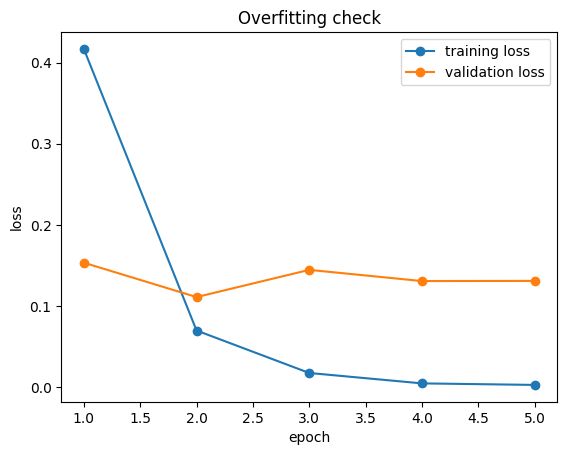

Lowest validation loss at epoch 2.0 -> this is the model kept
Step 4b: evaluate on testing data


{'test_accuracy': 0.9605, 'test_samples': 962, 'test_runtime_s': 5.09, 'test_samples_per_second': 189.2}
               precision    recall  f1-score   support

        Blusa       0.85      0.92      0.88        74
        Bolsa       1.00      0.96      0.98        56
   Calcetines       1.00      0.99      0.99        81
       Camisa       0.95      0.99      0.97        72
        Jeans       0.95      0.83      0.88        69
Lentes de sol       1.00      1.00      1.00        57
      Mochila       0.97      1.00      0.99        75
     Pantalón       0.87      0.97      0.92        69
      Playera       0.98      0.85      0.91        61
        Reloj       1.00      1.00      1.00        80
    Sandalias       1.00      0.99      0.99        70
        Short       0.99      0.99      0.99        71
        Tenis       0.98      0.98      0.98        66
      Vestido       0.94      0.97      0.95        61

     accuracy                           0.96       962
    macro avg

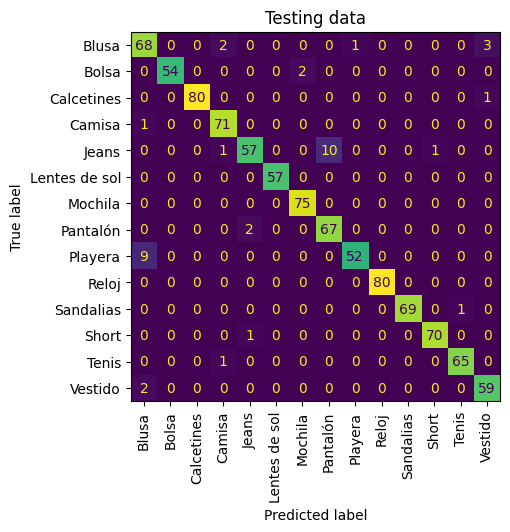

Step 4c: save
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Device set to use cuda:0


Copied to MyDrive/Models: ['fine_tuned_model.zip', 'dataset_files.zip', 'results.zip']
Step 5: test the saved model
true: Blusa          predicted: Vestido        score: 0.99
true: Tenis          predicted: Tenis          score: 1.00
true: Short          predicted: Short          score: 1.00
true: Reloj          predicted: Reloj          score: 1.00
true: Tenis          predicted: Tenis          score: 1.00
true: Lentes de sol  predicted: Lentes de sol  score: 1.00
true: Short          predicted: Short          score: 1.00
true: Reloj          predicted: Reloj          score: 1.00


In [22]:
def main():
    print("Step 1: dataset")
    dataset, table = load_and_balance()
    splits = split_by_product(table)
    counts = describe(splits)
    data = make_dataset(dataset, splits)

    print("Step 2: model")
    model, processor = create_model()

    print("Step 3: prepare data")
    training_data = prepare_for_training(data, processor)

    print("Step 4a: fine-tune")
    trainer = finetune(model, training_data)
    epochs_table = loss_per_epoch(trainer)

    print("Step 4b: evaluate on testing data")
    test_results = evaluate_on_test(trainer, training_data)

    print("Step 4c: save")
    save_everything(trainer, processor, data, counts, epochs_table, test_results)

    print("Step 5: test the saved model")
    test_saved_model(data)


if __name__ == "__main__":
    main()